# Módulo 6 — Entregable final del curso: proyecto integrador

Pasos 4 y 5 de la práctica del **Día 10** (ver [`README.md`](../README.md)):
documentar el resultado del caso ejecutado en
[`03_practica_ejecucion_completa.ipynb`](03_practica_ejecucion_completa.ipynb)
y cerrar el curso. **Este notebook es el entregable de evaluación final**,
en el mismo formato descrito en la propuesta del curso: notebook Jupyter
documentado con los resultados.

## 1. Resumen del caso analizado

In [1]:
import sys, os
BASE = "proyecto_demo"
sys.path.insert(0, BASE)
sys.path.insert(0, f"{BASE}/pipeline")

import importlib
import config as cfg
importlib.reload(cfg)

import pandas as pd

print("Caso de estudio (Módulo 6, ejecutado en 03_practica_ejecucion_completa.ipynb):")
for k, v in cfg.CASO.items():
    print(f"  {k}: {v}")

Caso de estudio (Módulo 6, ejecutado en 03_practica_ejecucion_completa.ipynb):
  fecha_inicio: 2025-03-14
  fecha_fin: 2025-03-17
  area: [-9, -80, -15, -74]
  estacion_validacion: {'nombre': 'Lima-Callao', 'lat': -12.0167, 'lon': -77.1167, 'archivo_obs': 'Lima_2025_03_horario.csv'}
  seed: 777
  nombre: Lima, marzo 2025
  estaciones_senamhi: estaciones_lima.json
  ciclo_gfs: 2025-03-14 00:00
  horas_gfs: [0, 3, 6, 9, 12, 15, 18, 21, 24, 27, 30, 33, 36, 39, 42, 45, 48, 51, 54, 57, 60, 63, 66, 69, 72]


## 2. Producto de entrada (Módulo 3)

In [2]:
import xarray as xr

archivo_entrada = f"{cfg.RUTAS['entrada']}/{cfg.CASO['fecha_inicio']}_{cfg.CASO['fecha_fin']}.nc"
ds_entrada = xr.open_dataset(archivo_entrada)
print(f"Archivo de entrada: {archivo_entrada}")
print(f"Variables: {list(ds_entrada.data_vars)}")
print(f"Cobertura temporal: {ds_entrada.sizes['time']} pasos horarios")

/home/japq/.conda/envs/jap/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Archivo de entrada: proyecto_demo/datos/entrada/2025-03-14_2025-03-17.nc
Variables: ['t2m', 'msl']
Cobertura temporal: 73 pasos horarios


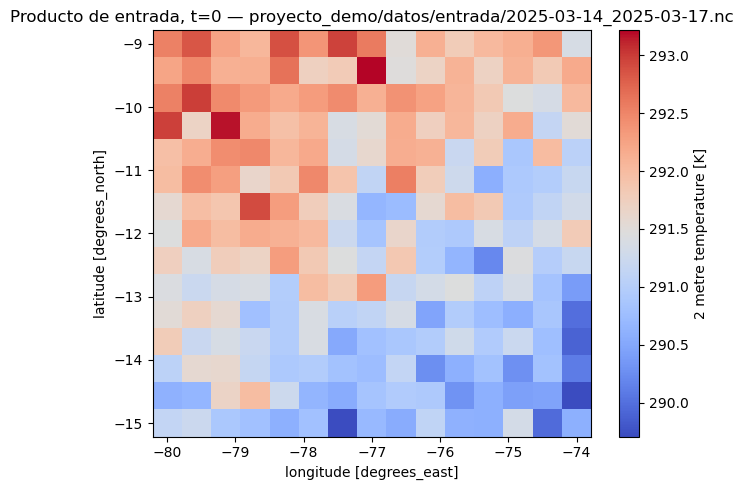

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.5, 5))
ds_entrada["t2m"].isel(time=0).plot(ax=ax, cmap="coolwarm")
ax.set_title(f"Producto de entrada, t=0 — {archivo_entrada}")
fig.tight_layout()
plt.show()

## 3. Producto de salida (Módulo 4)

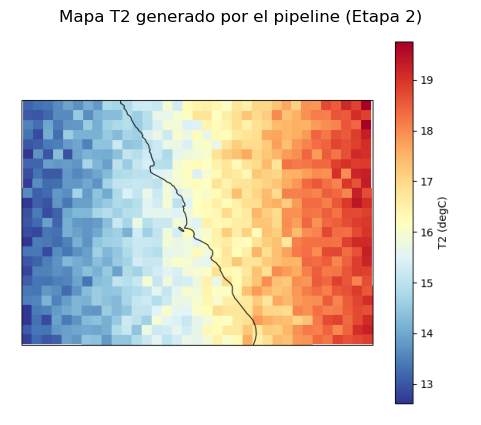

In [4]:
from PIL import Image
import matplotlib.pyplot as plt

ruta_mapa = f"{cfg.RUTAS['resultados_mapas']}/t2_caso_nuevo.png"
img = Image.open(ruta_mapa)
plt.figure(figsize=(6, 5))
plt.imshow(img)
plt.axis("off")
plt.title("Mapa T2 generado por el pipeline (Etapa 2)")
plt.show()

## 4. Producto de validación (Módulo 5)

In [5]:
tabla_validacion = pd.read_csv(f"{cfg.RUTAS['resultados_validacion']}/validacion_caso_nuevo.csv", index_col=0)
tabla_validacion

,variable,MAE,RMSE,bias,r,KGE
estacion,,,,,,
Lima (todos los datos),T2,1.281,2.147,1.010,0.574,0.441
Lima (sin el dato dudoso),T2,0.970,1.269,0.687,0.837,0.715


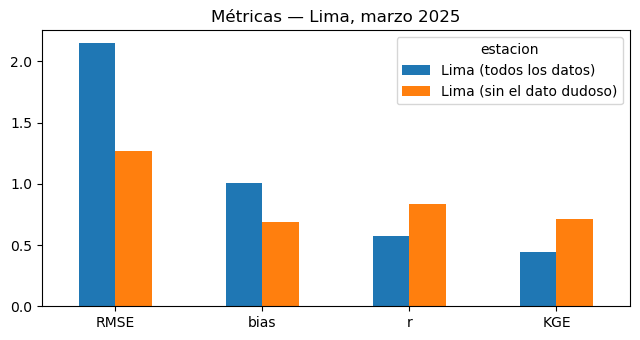

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
tabla_validacion[["RMSE", "bias", "r", "KGE"]].T.plot(kind="bar", ax=ax)
ax.axhline(0, color="k", linewidth=0.7)
ax.set_title(f"Métricas — {cfg.CASO['nombre']}")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

In [7]:
todos = tabla_validacion.iloc[0]
limpio = tabla_validacion.iloc[1]
estacion = cfg.CASO["estacion_validacion"]["nombre"]

print(f'''
Pronóstico GFS (ciclo {cfg.CASO["ciclo_gfs"]} UTC) vs. estación {estacion}

                      r      RMSE    sesgo
  todos los datos   {todos["r"]:5.2f}  {todos["RMSE"]:5.2f} °C  {todos["bias"]:+5.2f} °C
  sin dato dudoso   {limpio["r"]:5.2f}  {limpio["RMSE"]:5.2f} °C  {limpio["bias"]:+5.2f} °C

Sin el dato dudoso, GFS es en promedio {abs(limpio["bias"]):.1f} °C más
{"cálido" if limpio["bias"] > 0 else "frío"} que la estación y sigue bien el ciclo del día (r = {limpio["r"]:.2f}).
''')


Pronóstico GFS (ciclo 2025-03-14 00:00 UTC) vs. estación Lima-Callao

                      r      RMSE    sesgo
  todos los datos    0.57   2.15 °C  +1.01 °C
  sin dato dudoso    0.84   1.27 °C  +0.69 °C

Sin el dato dudoso, GFS es en promedio 0.7 °C más
cálido que la estación y sigue bien el ciclo del día (r = 0.84).



### Las 5 estaciones de SENAMHI

In [8]:
tabla_senamhi = pd.read_csv(f"{cfg.RUTAS['resultados_validacion']}/validacion_senamhi.csv", index_col=0)
tabla_senamhi[["bias", "RMSE", "r", "KGE"]].round(2)

,bias,RMSE,r,KGE
estacion,,,,
San Martin De Porres (56 m),-0.25,1.07,0.85,0.72
Campo De Marte (117 m),0.27,1.29,0.80,0.65
Von Humboldt (247 m),-0.71,1.96,0.82,0.47
Ceres (339 m),-1.75,2.24,0.82,0.59
Ñaña (553 m),-3.44,3.48,0.97,0.84


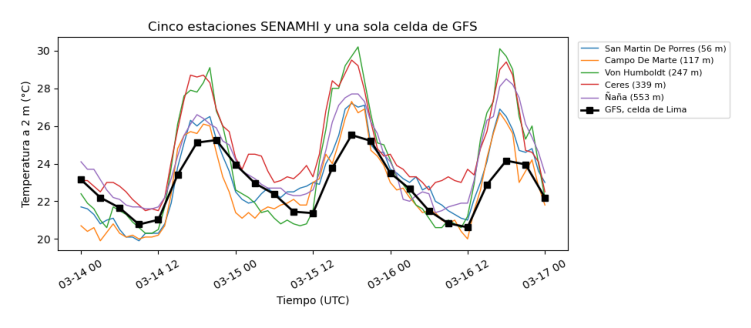

In [9]:
ruta_serie = f"{cfg.RUTAS['resultados_series']}/serie_senamhi.png"
plt.figure(figsize=(9.5, 4))
plt.imshow(Image.open(ruta_serie))
plt.axis("off")
plt.show()

**Tu conclusión (3 o 4 líneas, con tus palabras):** ¿qué tan bien
pronosticó GFS la temperatura en Lima? ¿Qué cambió al quitar el dato
dudoso de Lima-Callao? Si GFS les da el mismo valor a cuatro estaciones,
¿por qué el error cambia de una a otra? ¿Qué esperarías de un WRF con
celdas más finas sobre la costa?

*Escribe aquí...*

## 5. Checklist de reproducibilidad

In [10]:
checklist = {
    "config.py existe y centraliza los parámetros del caso": os.path.exists(f"{BASE}/config.py"),
    "pipeline/descarga.py existe": os.path.exists(f"{BASE}/pipeline/descarga.py"),
    "pipeline/visualizacion.py existe": os.path.exists(f"{BASE}/pipeline/visualizacion.py"),
    "pipeline/validacion.py existe": os.path.exists(f"{BASE}/pipeline/validacion.py"),
    "entorno.txt (versiones fijadas) existe": os.path.exists(f"{BASE}/entorno.txt"),
    "datos/ y resultados/ están separados": os.path.isdir(f"{BASE}/datos") and os.path.isdir(f"{BASE}/resultados"),
}

for item, ok in checklist.items():
    marca = "✓" if ok else "✗"
    print(f"  [{marca}] {item}")

print()
print("¿Pipeline completo y reproducible?", all(checklist.values()))

  [✓] config.py existe y centraliza los parámetros del caso
  [✓] pipeline/descarga.py existe
  [✓] pipeline/visualizacion.py existe
  [✓] pipeline/validacion.py existe
  [✓] entorno.txt (versiones fijadas) existe
  [✓] datos/ y resultados/ están separados

¿Pipeline completo y reproducible? True


## Guardar el proyecto con Git (15 min)

Git guarda la historia del proyecto: qué cambió y cuándo. Abre una terminal
en la carpeta `proyecto_demo/` y ejecuta:

```bash
git init                          # empezar a llevar historia aquí
echo "datos/" > .gitignore        # los datos pesados NO se guardan en Git
echo "resultados/" >> .gitignore  # se pueden volver a generar
git add .
git commit -m "Pipeline del proyecto final"
git log --oneline                 # ver la historia
```

**Regla:** en Git va el código y la configuración (`pipeline/`, `config.py`,
este notebook, `environment.yml`); los datos y resultados no, porque pesan
mucho y se regeneran corriendo el pipeline.


## 6. Cierre del curso

A lo largo de las 50 horas del curso se construyó, módulo a módulo, un
pipeline completo para el ciclo de trabajo de un usuario de WRF con Python:

| Módulo | Aporte al pipeline |
|---|---|
| 1 — Python básico | Fundamentos de Python, NumPy, Xarray, Pandas, Matplotlib |
| 2 — Formatos de datos | Lectura/recorte/interpolación de NetCDF y GRIB |
| 3 — Descarga de entrada | `pipeline/descarga.py` |
| 4 — Salidas del WRF | `pipeline/visualizacion.py` |
| 5 — Validación | `pipeline/validacion.py` |
| 6 — Integración | `config.py` + orquestación de punta a punta |

**Recomendaciones para continuar después del curso:**
- Cambiar la serie de GFS por la de su propia corrida del WRF sobre Lima:
  en la Etapa 3 solo cambia `sim`.
- Reemplazar los generadores sintéticos (`synth_data_*.py`) de las
  Etapas 1 y 2 por las descargas reales (`cdsapi`) una vez configuradas
  las credenciales propias.
- Versionar el proyecto con Git desde el primer commit.
- Considerar paralelizar la descarga de múltiples casos y programar
  ejecuciones recurrentes si el flujo se usa de forma operativa.